In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import statsmodels.api as sm
from eda_manager.analyze.data_analyze import (CorrelationAnalyze, Preprocessor,
                                              VariableSelector, ResidualAnalyzer, PredictAnalyzer)

https://data-minggeul.tistory.com/10

https://cn-c.tistory.com/67#google_vignette

https://sy-log.tistory.com/entry/%ED%9A%8C%EA%B7%80%EB%AA%A8%EB%8D%B8-%ED%8F%89%EA%B0%80%EC%A7%80%ED%91%9C-R2-score-%EA%B2%B0%EC%A0%95%EA%B3%84%EC%88%98-MAE-MSE-RMSE-MAPE-MPE#google_vignette

https://sy-log.tistory.com/entry/%EB%B6%84%EB%A5%98%EB%AA%A8%EB%8D%B8-%ED%8F%89%EA%B0%80%EC%A7%80%ED%91%9C-%EC%98%A4%EC%B0%A8%ED%96%89%EB%A0%AC-%ED%98%BC%EB%8F%99%ED%96%89%EB%A0%AC-%EC%A0%95%ED%99%95%EB%8F%84-%EC%9E%AC%ED%98%84%EC%9C%A8-%EC%A0%95%EB%B0%80%EB%8F%84-F1-score-ROC%EA%B3%A1%EC%84%A0-AUC?category=1233809

https://nanunzoey.tistory.com/entry/ROC-%EA%B3%A1%EC%84%A0-vs-P-R-%EA%B3%A1%EC%84%A0

In [2]:
%matplotlib inline

In [3]:
titanic = sns.load_dataset("titanic").dropna(subset=["age","sex","class","embarked","survived"])
num_cols = ["age","fare"]
cat_cols = ["sex","class","embarked"]
selection_method = 'stepwise'
scaler = 'minmax'
impute = 'remove'
test_ratio = 0.2

X = titanic[["age","fare","sex","class","embarked"]]
y = titanic["survived"]

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=test_ratio, random_state=42)
prep = Preprocessor(num_cols=num_cols, cat_cols=cat_cols, scaler=scaler, impute=impute)
X_train_proc, y_train_enc = prep.fit_transform(X_train, y_train)
X_test_proc, y_test_enc = prep.transform(X_test, y_test)
sel = None
if len(cat_cols)>0:
    sel = VariableSelector(X_train_proc, y_train_enc, method=selection_method,
                            model_type="auto", group_map=prep.group_map)
else:
    sel = VariableSelector(X_train_proc, y_train_enc, method=selection_method,
                            model_type="auto")
res = sel.select()

In [8]:
y_actual = res['y']
y_proba = res['y_proba']
pos_label = int(y_actual.unique().max())

ROC Curve

In [9]:
from sklearn.metrics import roc_curve, auc, RocCurveDisplay, confusion_matrix
import numpy as np

fpr, tpr, thresholds = roc_curve(y_actual, y_proba, pos_label=pos_label)
roc_auc = auc(fpr, tpr)
distances = np.sqrt((1-tpr)**2 + (fpr)**2)
optimal_idx = np.argmin(distances)

opt_thr = thresholds[optimal_idx]
opt_fpr, opt_tpr = fpr[optimal_idx], tpr[optimal_idx]
print(opt_fpr, opt_tpr, opt_thr)

0.2441860465116279 0.8488888888888889 0.35665420479268145


In [13]:
type(pos_label)

int

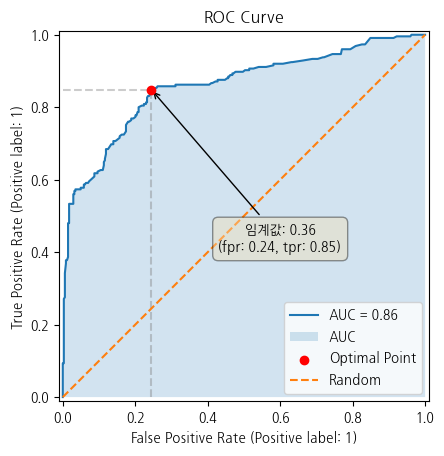

In [10]:
fig, ax = plt.subplots()
display = RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc, pos_label=pos_label)
display.plot(ax=ax)
ax.fill_between(fpr, tpr, alpha=0.2, label='AUC')
ax.plot([0, opt_fpr], [opt_tpr]*2, color='gray', ls='--', alpha=0.4)
ax.plot([opt_fpr]*2, [0, opt_tpr], color='gray', ls='--', alpha=0.4)
ax.scatter([opt_fpr], [opt_tpr], c='r', label='Optimal Point', zorder=10)
ax.annotate(text=f"임계값: {opt_thr:.2f}\n(fpr: {opt_fpr:.2f}, tpr: {opt_tpr:.2f})", 
            xy=(opt_fpr, opt_tpr),
            xytext=[0.6,0.4],
            bbox=dict(boxstyle='round', pad=0.4, fc='wheat', alpha=0.4),
            arrowprops=dict(arrowstyle='->'),
            ha='center')
ax.plot([0,1],[0,1], ls='--', label='Random')
ax.legend()
ax.set_title("ROC Curve")
plt.show()

In [16]:
y_pred = (y_proba >= opt_thr).astype(int)

In [17]:
type(y_pred)

pandas.core.series.Series

In [9]:
tn, fp, fn, tp = confusion_matrix(y_actual, y_pred).ravel().tolist()

print(f"TP: {tp: ,}")
print(f"TN: {tn: ,}")
print(f"FP: {fp: ,}")
print(f"FN: {fn: ,}")

TP:  191
TN:  260
FP:  84
FN:  34


In [10]:
accuracy = (tp+tn)/(tp+tn+fp+fn)
precision = tp/(tp+fp)
recall = tp/(tp+fn)
specificity = tn/(tn+fp)
f1_score = 2*precision*recall/(precision+recall)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"Specificity: {specificity: .4f}")
print(f"F1-Score: {f1_score:.4f}")
print(f"ROC AUC: {roc_auc: .4f}")

Accuracy: 0.7926
Precision: 0.6945
Recall: 0.8489
Specificity:  0.7558
F1-Score: 0.7640
ROC AUC:  0.8590


PR Curve

In [18]:
from sklearn.metrics import precision_recall_curve, PrecisionRecallDisplay
precisions, recalls, thresholds = precision_recall_curve(y_actual, y_proba, pos_label=pos_label)
pr_auc = auc(recalls, precisions)
f1_scores = 2*precisions*recalls/(precisions+recalls)
optimal_idx = np.argmax(f1_scores)
opt_thr = thresholds[optimal_idx]
opt_precision, opt_recall = precisions[optimal_idx], recalls[optimal_idx]
opt_f1_score = f1_scores[optimal_idx]
print(opt_precision, opt_recall, opt_thr, opt_f1_score)

0.6945454545454546 0.8488888888888889 0.35665420479268145 0.7639999999999999


In [20]:
type(precisions)

numpy.ndarray

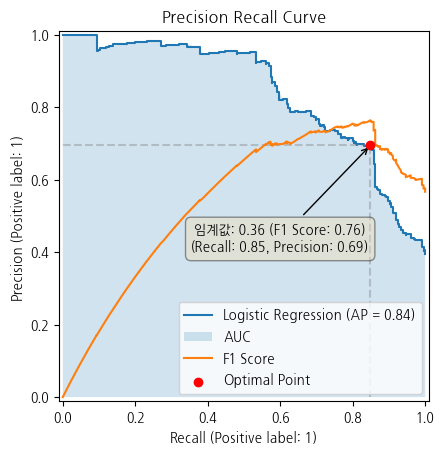

In [19]:
fig, ax = plt.subplots()
display = PrecisionRecallDisplay(precision=precisions, recall=recalls, pos_label=pos_label, average_precision=pr_auc,estimator_name='Logistic Regression')
display.plot(ax=ax)
ax.fill_between(recalls, precisions, alpha=0.2, label='AUC')
ax.plot([0, opt_recall], [opt_precision]*2, color='gray', ls='--', alpha=0.4)
ax.plot([opt_recall]*2, [0, opt_precision], color='gray', ls='--', alpha=0.4)
ax.plot(recalls, f1_scores, label='F1 Score')
ax.scatter([opt_recall], [opt_precision], c='r', label='Optimal Point', zorder=10)
ax.annotate(text=f"임계값: {opt_thr:.2f} (F1 Score: {opt_f1_score:.2f})\n(Recall: {opt_recall:.2f}, Precision: {opt_precision:.2f})", 
            xy=(opt_recall, opt_precision),
            xytext=[0.6,0.4],
            bbox=dict(boxstyle='round', pad=0.4, fc='wheat', alpha=0.4),
            arrowprops=dict(arrowstyle='->'),
            ha='center')
ax.legend(loc='lower right')
ax.set_title("Precision Recall Curve")
plt.show()

In [13]:
y_pred = (y_proba >= opt_thr).astype(int)

In [14]:
tn, fp, fn, tp = confusion_matrix(y_actual, y_pred).ravel().tolist()

print(f"TP: {tp: ,}")
print(f"TN: {tn: ,}")
print(f"FP: {fp: ,}")
print(f"FN: {fn: ,}")

TP:  191
TN:  260
FP:  84
FN:  34


In [15]:
accuracy = (tp+tn)/(tp+tn+fp+fn)
precision = tp/(tp+fp)
recall = tp/(tp+fn)
specificity = tn/(tn+fp)
f1_score = 2*precision*recall/(precision+recall)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"Specificity: {specificity: .4f}")
print(f"F1-Score: {f1_score:.4f}")
print(f"ROC AUC: {roc_auc: .4f}")

Accuracy: 0.7926
Precision: 0.6945
Recall: 0.8489
Specificity:  0.7558
F1-Score: 0.7640
ROC AUC:  0.8590


In [16]:
print(tn, fp, fn, tp)

260 84 34 191
